### Notebook to overlay qMSI and Stereo-seq sections
#### Tissues: IRI1, IRI2, IRI3

In [42]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import anndata as ad
import scanpy as sc
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.cm import get_cmap
from scipy.spatial import cKDTree

import warnings
warnings.filterwarnings("ignore")

#### Read qMSI

In [43]:
# Banksy result 
qmsi_biri_sd = pd.read_csv("qmsi/bIRI_banksy_QMSI_RPCA_lambda1_kgeom8_res1_agftrue_scalefalse_130lipids_NOgaps.csv",index_col=0)
qmsi_sham_sd = pd.read_csv("qmsi/SHAM_banksy_QMSI_RPCA_lambda1_kgeom8_res1_agftrue_scalefalse_130lipids_NOgaps.csv",index_col=0)

# Coord bIRI
biri_coord = pd.read_csv("qmsi/xycoords_iri.csv",index_col=0)
sham_coord = pd.read_csv("qmsi/xycoords_sham.csv",index_col=0)

# filter out gaps from coordinate files
biri_coord = biri_coord[biri_coord.index.isin(qmsi_biri_sd.index)]
sham_coord = sham_coord[sham_coord.index.isin(qmsi_sham_sd.index)]

# add coordinates to Banksy result df 
qmsi_biri_sd[['x','y']] = biri_coord[['x','y']]
qmsi_sham_sd[['x','y']] = sham_coord[['x','y']]

### Read Stereo-seq

In [44]:
# read Banksy results
result_biri = pd.read_csv("stseq/df_biri.csv",index_col=0)

# read metadata
ad_obj_metadata = pd.read_csv("stseq/ad_obj_metadata.csv",index_col=0)
# read the new annotations (from 3rd of July)
barcode_ann = pd.read_csv("stseq/barcode_annotation.csv",index_col=0)

barcode_ann['_group'] = barcode_ann.index.str[-1] # fix index

# Create two separate DataFrames based on the grouping
sham_ann = barcode_ann[barcode_ann['_group'].isin(['1', '2', '3'])].copy()
biri_ann = barcode_ann[barcode_ann['_group'].isin(['4', '5', '6'])].copy()

biri_ann.drop('_group', axis=1, inplace=True)
sham_ann.drop('_group', axis=1, inplace=True)

biri_ann.index = biri_ann.index.str[:-2]
sham_ann.index = sham_ann.index.str[:-2]

biri_ann.index = biri_ann.index+'_biri'
sham_ann.index = sham_ann.index+'_sham'

ann = pd.concat([biri_ann,sham_ann],axis=0)

# add them to the h5ad object metadata
ad_obj_metadata['new_CT_annotation'] = ann['x']

# Subset data to only have either IRI or sham (since they are same coordinate space)
ad_obj_biri = ad_obj_metadata[ad_obj_metadata['kidney_n'].str.startswith('bIRI')]
ad_obj_sham = ad_obj_metadata[ad_obj_metadata['kidney_n'].str.startswith('Sham')]

ad_obj_biri.index = ad_obj_biri.index.astype(str).str[:-5]
ad_obj_sham.index = ad_obj_sham.index.astype(str).str[:-5]

# filter
ad_obj_biri = ad_obj_biri[ad_obj_biri.index.isin(result_biri.index)]
#ad_obj_sham = ad_obj_sham[ad_obj_sham.index.isin(result_sham.index)]

# rename index and column
result_biri.index = ad_obj_biri.index
ad_obj_biri['banksy_l1_k8_res1'] = result_biri['clust_M1_lam1_k50_res1']

#result_sham.index = ad_obj_sham.obs.index
#ad_obj_sham.obs['banksy_l1_k8_res1'] = result_sham['clust_M1_lam1_k50_res1']

# QC filter

ad_obj_biri = ad_obj_biri[ad_obj_biri['percent.mt']<10]
ad_obj_biri = ad_obj_biri[(ad_obj_biri['nFeature_RNA']>200) & (ad_obj_biri['nFeature_RNA']<2500)]

ad_obj_sham = ad_obj_sham[ad_obj_sham['percent.mt']<10]
ad_obj_sham = ad_obj_sham[(ad_obj_sham['nFeature_RNA']>200) & (ad_obj_sham['nFeature_RNA']<2500)]

#### Subset to keep only bIRI1

In [45]:
biri_ss = ad_obj_biri[ad_obj_biri.kidney_n == 'bIRI1']
biri_qmsi = qmsi_biri_sd[qmsi_biri_sd['kidney'] == 'biri1']

##### Scatterplot raw coordinates

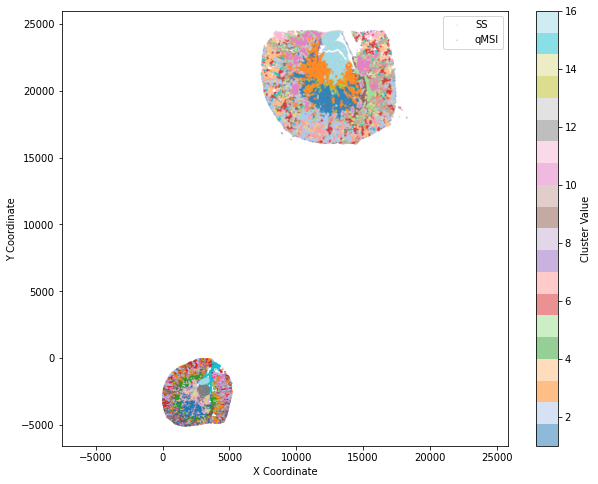

In [46]:
def plot_scatter(df1, df2):
    plt.figure(figsize=(10, 8))

    cmap = get_cmap('tab20')

    scatter1 = plt.scatter(df1['x'], df1['y'], c=df1['banksy_l1_k8_res1'],
                           cmap=cmap, label='SS', alpha=0.5, s=0.1)
    scatter2 = plt.scatter(df2['x'], df2['y'], c=df2['clust_M1_lam1_k50_res1'], cmap=cmap, label='qMSI', alpha=0.5, s=0.1)

    plt.colorbar(scatter2, label='Cluster Value')

    plt.xlabel('X Coordinate')
    plt.ylabel('Y Coordinate')
    plt.legend()
    plt.axis('equal') 

    plt.show()

plot_scatter(biri_ss, biri_qmsi)

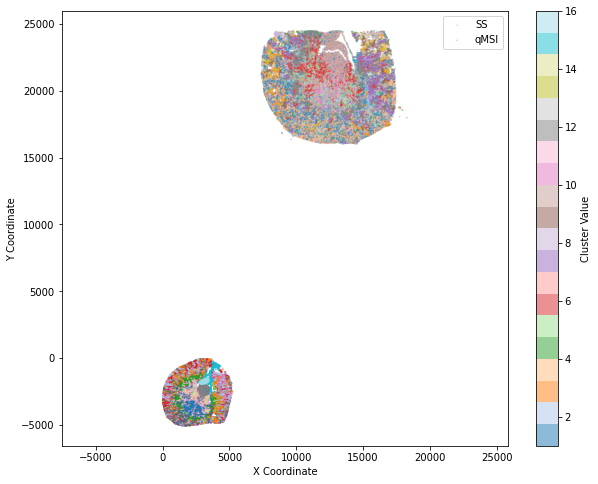

In [47]:
def plot_scatter(df1, df2):
    plt.figure(figsize=(10, 8))

    cmap = get_cmap('tab20')

    scatter1 = plt.scatter(df1['x'], df1['y'], c=df1['Seurat_Clusters_Res1'], cmap=cmap, label='SS', alpha=0.5, s=0.1)
    scatter2 = plt.scatter(df2['x'], df2['y'], c=df2['clust_M1_lam1_k50_res1'], cmap=cmap, label='qMSI', alpha=0.5, s=0.1)

    plt.colorbar(scatter2, label='Cluster Value')

    plt.xlabel('X Coordinate')
    plt.ylabel('Y Coordinate')
    plt.legend()
    plt.axis('equal') 

    plt.show()

plot_scatter(biri_ss, biri_qmsi)

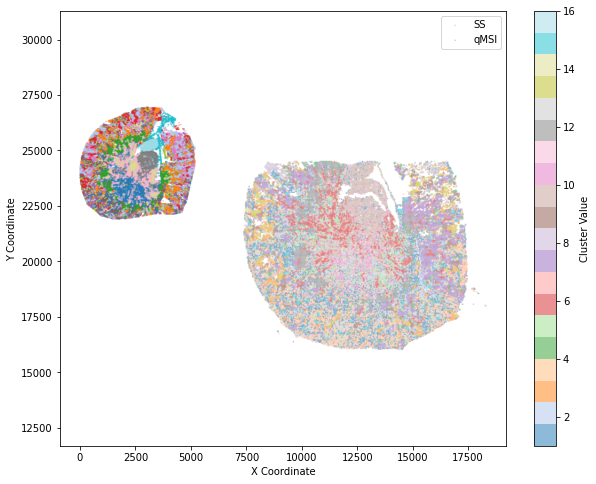

In [48]:
# translate x and y
biri_qmsi['y'] =  biri_qmsi['y']+27000
plot_scatter(biri_ss, biri_qmsi)

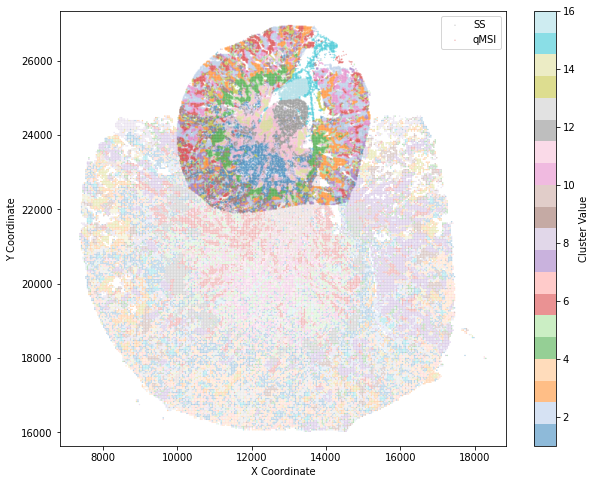

In [49]:
biri_qmsi['x'] =  biri_qmsi['x']+10000
plot_scatter(biri_ss, biri_qmsi)

In [50]:
# Function to rotate coordinates counterclockwise around the centroid
def rotate_coordinates(df, angle_degrees):
    # Calculate the centroid (mean of x and y)
    centroid_x = df['x'].mean()
    centroid_y = df['y'].mean()

    angle_radians = np.radians(angle_degrees)

    rotation_matrix = np.array([
        [np.cos(angle_radians), -np.sin(angle_radians)],
        [np.sin(angle_radians), np.cos(angle_radians)]
    ])

    shifted_coords = df[['x', 'y']].values - [centroid_x, centroid_y]

    rotated_coords = np.dot(shifted_coords, rotation_matrix.T)

    rotated_coords += [centroid_x, centroid_y]

    df['x'] = rotated_coords[:, 0]
    df['y'] = rotated_coords[:, 1]

    return df

df_rotated = rotate_coordinates(biri_qmsi, 20)

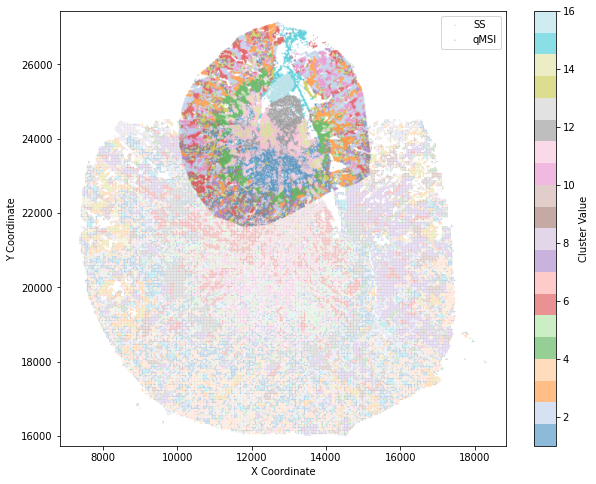

In [51]:
plot_scatter(biri_ss, df_rotated)

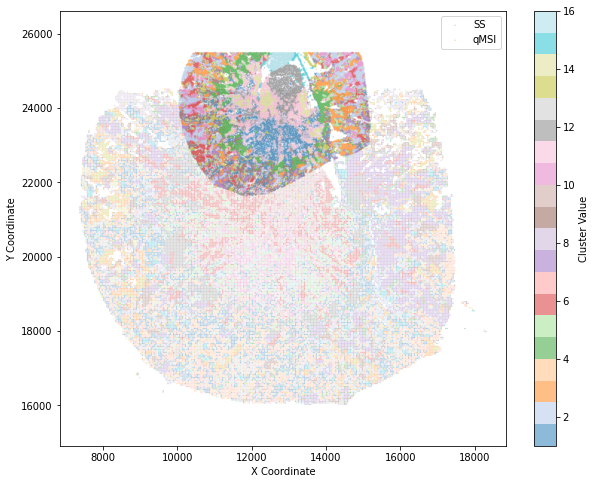

In [52]:
# remove spots y>25500 because stereo-seq is missing portion of the tissue
df_rotated = df_rotated[df_rotated['y']<25500]
plot_scatter(biri_ss, df_rotated)

In [53]:
def rescale_coordinates(df1, df2):
    x_min_df2, x_max_df2 = df2['x'].min(), df2['x'].max()
    y_min_df2, y_max_df2 = df2['y'].min(), df2['y'].max()

    x_min_df1, x_max_df1 = df1['x'].min(), df1['x'].max()
    y_min_df1, y_max_df1 = df1['y'].min(), df1['y'].max()

    df1['x'] = (df1['x'] - x_min_df1) / (x_max_df1 - x_min_df1) * (x_max_df2 - x_min_df2) + x_min_df2
    df1['y'] = (df1['y'] - y_min_df1) / (y_max_df1 - y_min_df1) * (y_max_df2 - y_min_df2) + y_min_df2

    return df1

In [54]:
qmsi_rescaled = rescale_coordinates(df_rotated, biri_ss)

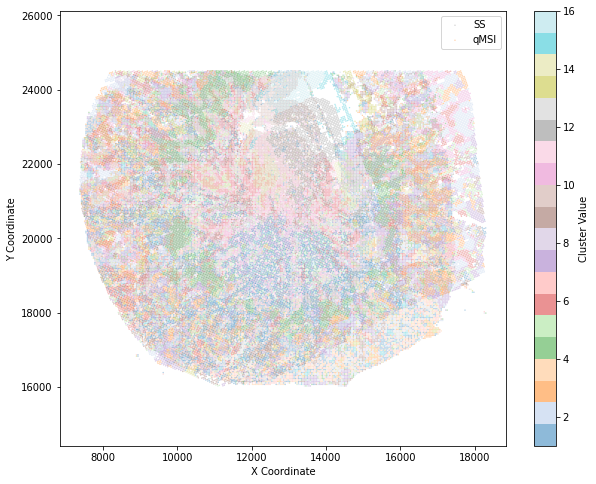

In [55]:
plot_scatter(biri_ss, qmsi_rescaled)

In [56]:
qmsi_rescaled['x'] = qmsi_rescaled['x']-400 # move x 

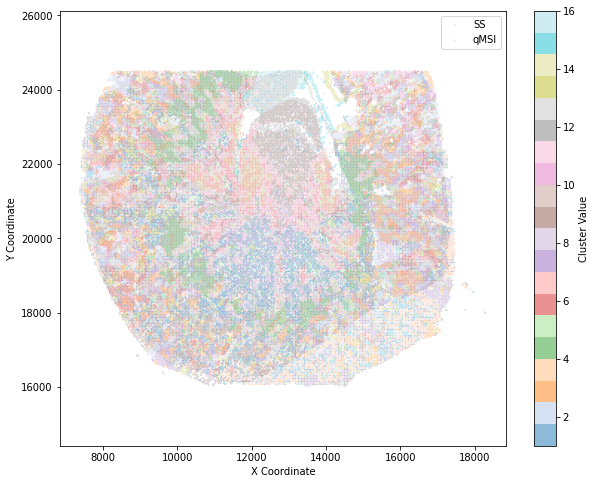

In [57]:
# shrink x by 0.9
x_center = qmsi_rescaled['x'].mean()

qmsi_rescaled['x'] = x_center + 0.9 * (qmsi_rescaled['x'] - x_center)

plot_scatter(biri_ss, qmsi_rescaled)

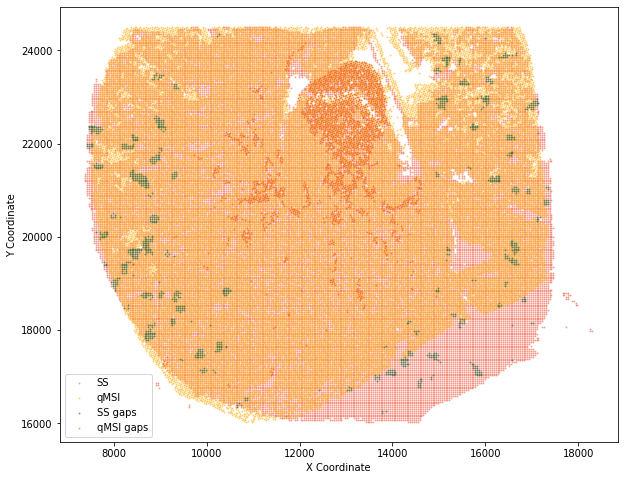

In [58]:
# color by GAPS SD
biri_qmsi_gaps = df_rotated[df_rotated['clust_M1_lam1_k50_res1'] == 12]
biri_ss_gaps = biri_ss[biri_ss['banksy_l1_k8_res1'] == 16]

def plot_gaps(df1, df2):
    plt.figure(figsize=(10, 8))

    plt.scatter(df1['x'], df1['y'], color='#f27059', label='SS', alpha=0.5, s=1)
    plt.scatter(df2['x'], df2['y'], color='#ffb627', label='qMSI', alpha=0.5, s=1)

    plt.scatter(biri_ss_gaps['x'], biri_ss_gaps['y'], color='#2c6e49', label='SS gaps', alpha=0.5, s=1)
    plt.scatter(biri_qmsi_gaps['x'], biri_qmsi_gaps['y'], color='#f26419', label='qMSI gaps', alpha=0.5, s=1)

    plt.xlabel('X Coordinate')
    plt.ylabel('Y Coordinate')
    plt.legend(loc='best')  
    plt.axis('equal') 

    plt.show()

plot_gaps(biri_ss, qmsi_rescaled)

In [59]:
qmsi_rescaled.drop(['sample_id'],axis=1,inplace=True)

In [60]:
qmsi_rescaled.to_csv('qmsi_transformed_biri1.csv')

#### Subset to keep only bIRI2

In [61]:
biri_ss = ad_obj_biri[ad_obj_biri.kidney_n == 'bIRI2']
biri_qmsi = qmsi_biri_sd[qmsi_biri_sd['kidney'] == 'biri3']

##### Scatterplot before

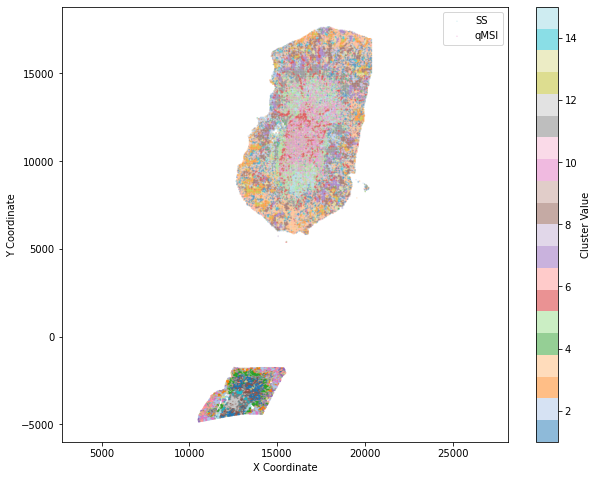

In [62]:
plot_scatter(biri_ss, biri_qmsi)

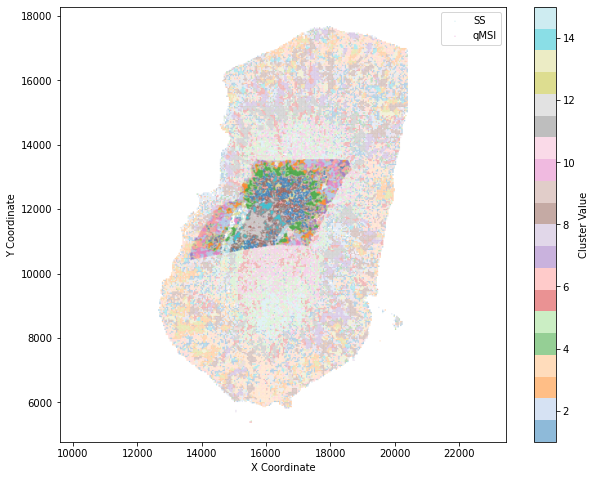

In [63]:
# translate x and y
biri_qmsi['y'] =  biri_qmsi['y']+15300
biri_qmsi['x'] =  biri_qmsi['x']+3150
plot_scatter(biri_ss, biri_qmsi)

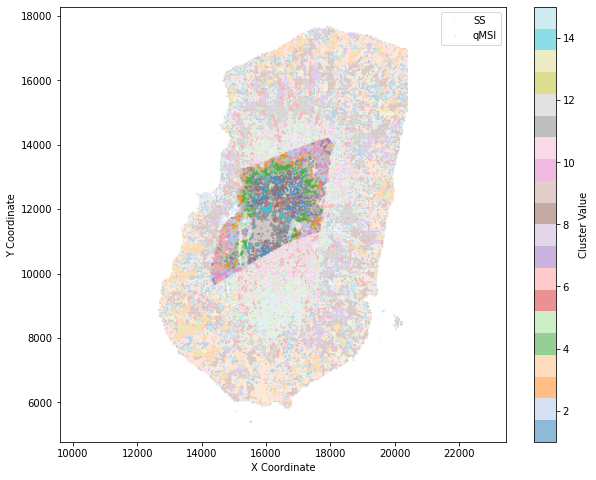

In [64]:
# rotate counterclockwise 20 degrees
df_rotated = rotate_coordinates(biri_qmsi, 20)
plot_scatter(biri_ss, df_rotated)

In [65]:
# rescale x only
def rescale_xcoordinates(df1, df2):
    x_min_df2, x_max_df2 = df2['x'].min(), df2['x'].max()
    x_min_df1, x_max_df1 = df1['x'].min(), df1['x'].max()

    df1['x'] = (df1['x'] - x_min_df1) / (x_max_df1 - x_min_df1) * (x_max_df2 - x_min_df2) + x_min_df2

    return df1

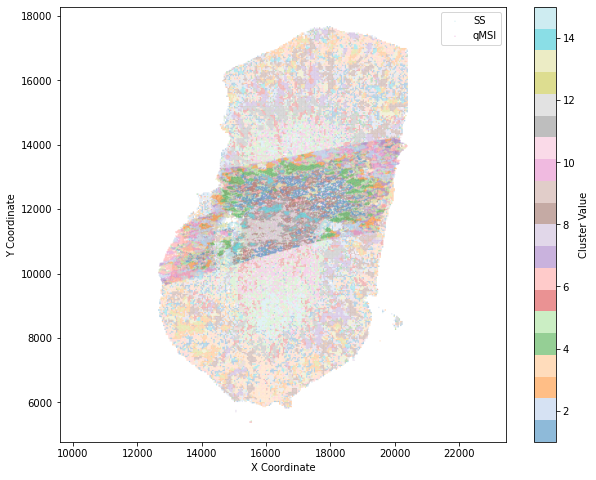

In [66]:
qmsi_rescaled = rescale_xcoordinates(df_rotated, biri_ss)
plot_scatter(biri_ss, qmsi_rescaled)

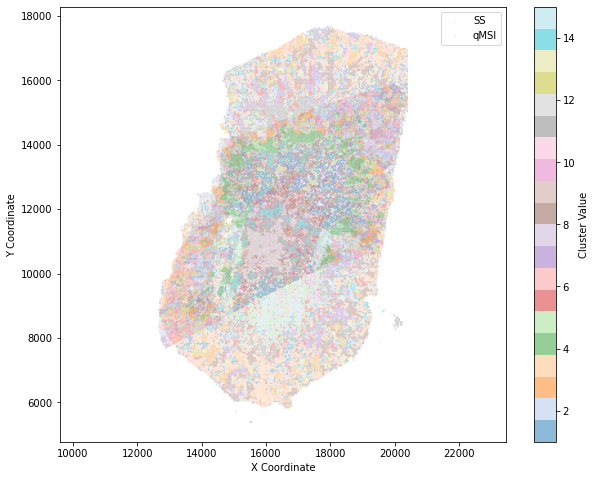

In [67]:
# rescale y by 1.5
x_center = qmsi_rescaled['y'].mean()
qmsi_rescaled['y'] = x_center + 1.8 * (qmsi_rescaled['y'] - x_center)

plot_scatter(biri_ss, qmsi_rescaled)

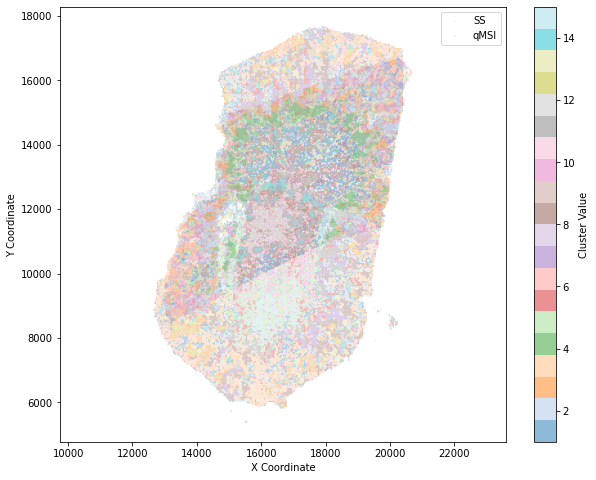

In [68]:
# translate y and x again
qmsi_rescaled['y'] =  qmsi_rescaled['y']+800
qmsi_rescaled['x'] =  qmsi_rescaled['x']+300

plot_scatter(biri_ss, qmsi_rescaled)

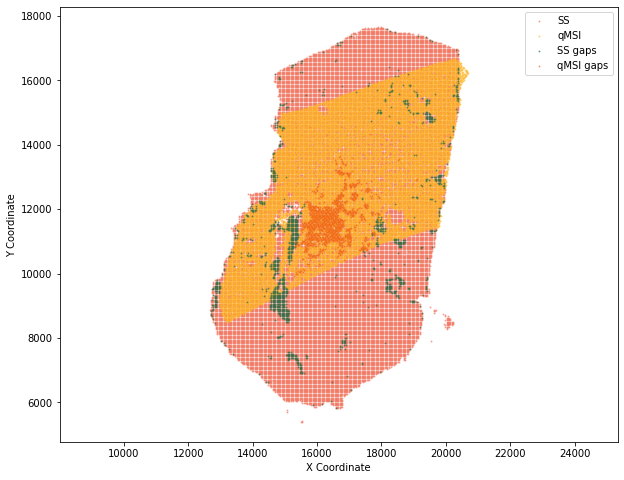

In [69]:
### plot GAPS SD
biri_qmsi_gaps = qmsi_rescaled[qmsi_rescaled['clust_M1_lam1_k50_res1'] == 12]
biri_ss_gaps = biri_ss[biri_ss['banksy_l1_k8_res1'] == 9]

plot_gaps(biri_ss, qmsi_rescaled)

In [70]:
qmsi_rescaled.drop(['sample_id'],axis=1,inplace=True)
qmsi_rescaled['kidney'] = 'biri2'

In [71]:
qmsi_rescaled

,kidney,clust_M1_lam1_k50_res1,x,y
Spot 213230,biri2,10,14876.011819,15001.317099
Spot 213231,biri2,10,14889.806724,14967.488165
Spot 213232,biri2,10,14927.707914,14979.800890
Spot 213233,biri2,13,14965.609103,14992.113615
Spot 213234,biri2,3,17656.593570,15866.317101
...,...,...,...,...
Spot 236367,biri2,7,13224.103193,8526.559553
Spot 236368,biri2,7,13262.004382,8538.872278
Spot 236369,biri2,7,13299.905572,8551.185003
Spot 236370,biri2,7,13337.806762,8563.497728


In [72]:
qmsi_rescaled.to_csv('qmsi_transformed_biri2.csv')

#### Subset to keep only bIRI2

In [73]:
biri_ss = ad_obj_biri[ad_obj_biri.kidney_n == 'bIRI3']
biri_qmsi = qmsi_biri_sd[qmsi_biri_sd['kidney'] == 'biri2']

##### Scatterplot before

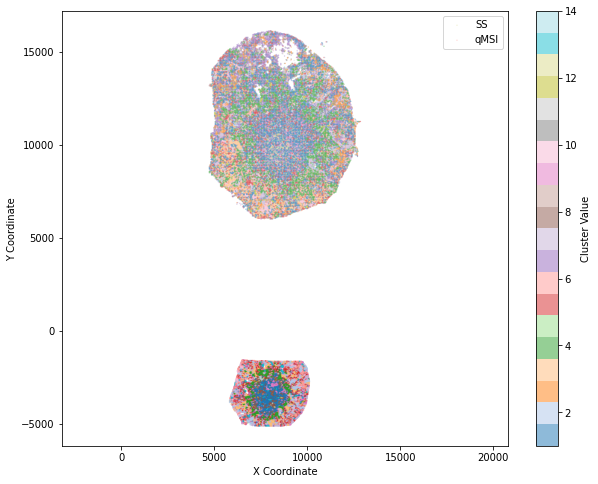

In [74]:
plot_scatter(biri_ss, biri_qmsi)

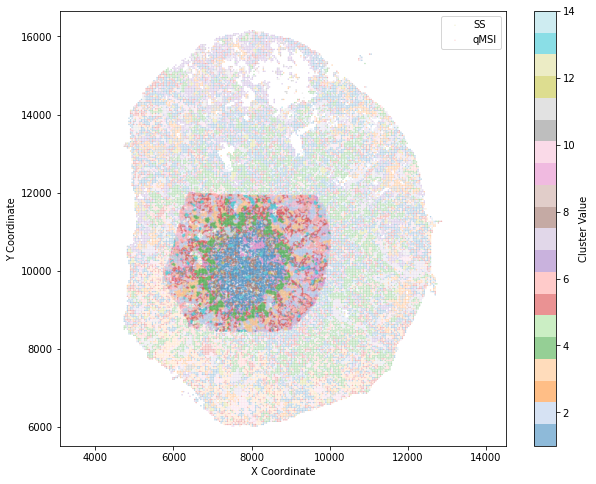

In [75]:
# translate x and y
biri_qmsi['y'] =  biri_qmsi['y']+13550
biri_qmsi['x'] =  biri_qmsi['x']-100
plot_scatter(biri_ss, biri_qmsi)

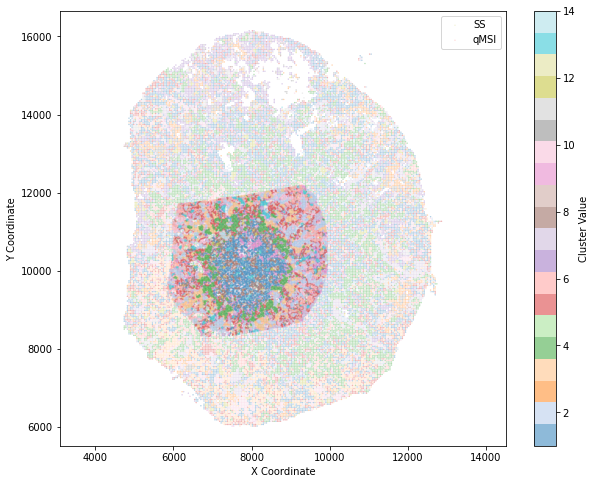

In [76]:
# rotate counterclockwise 10 degrees
df_rotated = rotate_coordinates(biri_qmsi, 10)
plot_scatter(biri_ss, df_rotated)

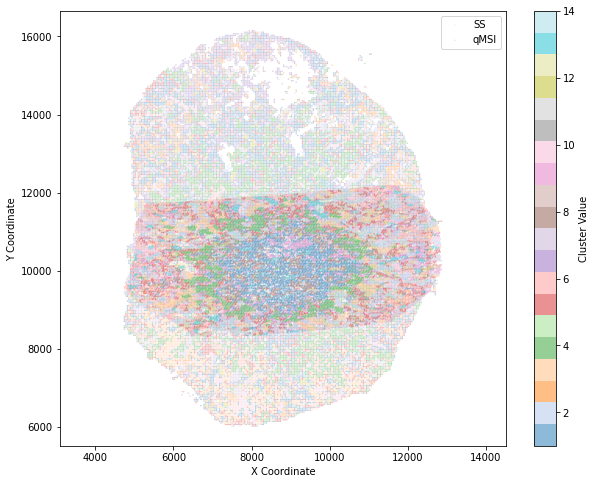

In [77]:
qmsi_rescaled = rescale_xcoordinates(biri_qmsi, biri_ss)
plot_scatter(biri_ss, qmsi_rescaled)

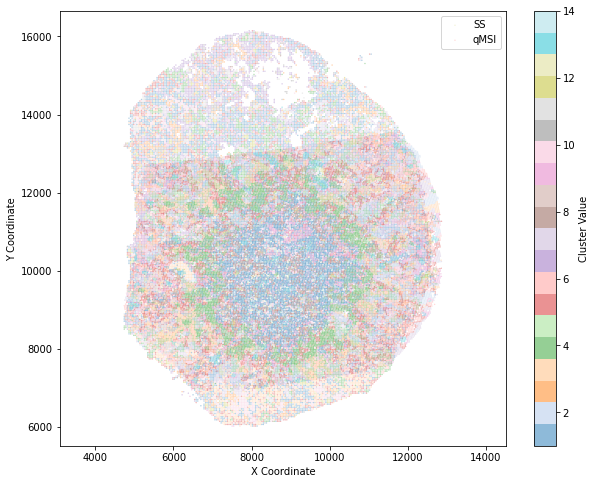

In [78]:
# rescale y by 1.7
x_center = qmsi_rescaled['y'].mean()
qmsi_rescaled['y'] = x_center + 1.7 * (qmsi_rescaled['y'] - x_center)

plot_scatter(biri_ss, qmsi_rescaled)

In [79]:
# translate x
qmsi_rescaled['x'] = qmsi_rescaled['x']-100

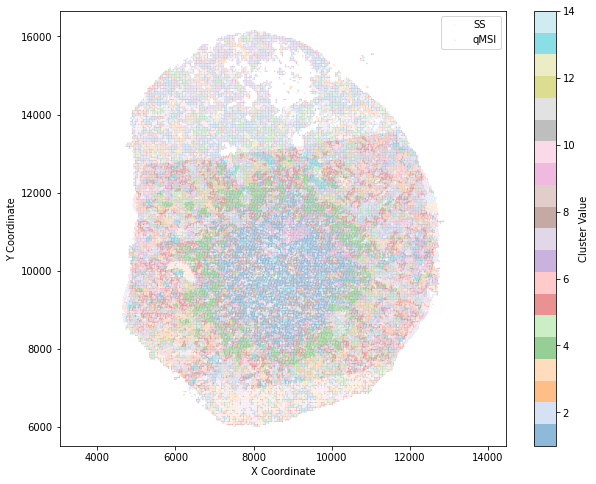

In [80]:
plot_scatter(biri_ss, qmsi_rescaled)

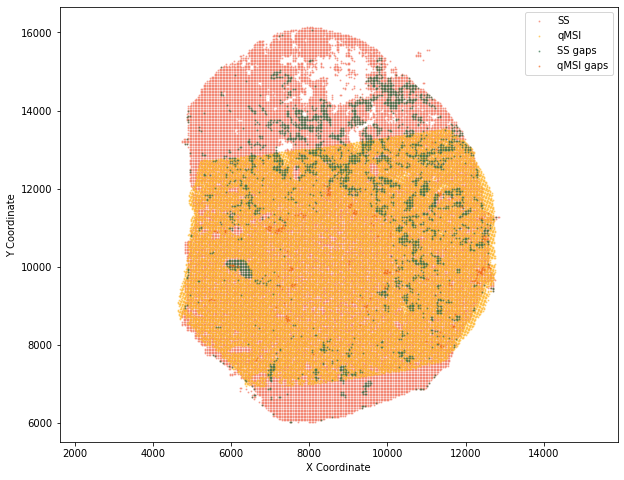

In [81]:
### plot GAPS SD
biri_qmsi_gaps = qmsi_rescaled[qmsi_rescaled['clust_M1_lam1_k50_res1'] == 12]
biri_ss_gaps = biri_ss[biri_ss['banksy_l1_k8_res1'] == 9]

plot_gaps(biri_ss, qmsi_rescaled)

In [82]:
qmsi_rescaled.drop(['sample_id'],axis=1,inplace=True)
qmsi_rescaled['kidney'] = 'biri3'

In [83]:
qmsi_rescaled.to_csv('qmsi_transformed_biri3.csv')